# Summary

## Tình huống

1.  Ứng Dụng: GrabMart
    - Chương trình khuyến mãi: Cross-sell mega promo (chương trình khuyến mãi chéo quy mô lớn)
    - Khoảng tgian thi triển: 6 tuần
    - Địa diểm: Thành Phố Hồ Chí Minh
    - Trạng Thái: thí điểm

2. Merchanism:
    Khi đặt đơn hàng trên `GrabFood`:
    constraints:
        - tổng giá trị > 100.000 vnđ -> nhận voucher trị giá 50.000 vnđ cho `GrabMart` tiếp theo

3. Output - Backlog Test:
    - Tổng giá trị giao dịch (GMV):
        + GrabMart và GrabFood: đều tăng hơn 45% (so với ?)

4. Deployment:
    - Triển khai chính thức tại Hà Nội (với ngân sách khủng)

5. Work-to-do: đưa ra đánh giá -- và phân tích răng có hợp lí để deploy ở Hà Nội không ?

    Tình huống:

        Giám đốc Quốc gia tin rằng chiến dịch này đã thành công trong việc thay đổi hành vi người dùng và 
        hình thành thói quen sử dụng đa dịch vụ.

    Câu hỏi:
        
        - Dựa trên dữ liệu chuyên sâu về hành vi và kết quả kinh doanh (P&L), bạn có đồng ý với nhận định này không?
        - Yếu tố thực sự nào đang thúc đẩy mức tăng trưởng 45% đó? 
        - Hãy xây dựng lập luận dựa trên dữ liệu và đưa ra khuyến nghị cuối cùng về việc có nên mở rộng chương trình này sang Hà Nội hay không 

## Import Libraries

In [79]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import numpy as np


## Create Connection to Database

In [15]:
conn = sqlite3.connect("grab_vn_case_analytics.db")

## Analytics view

### View table available

In [16]:
query = """
SELECT name, sql
FROM sqlite_master
WHERE type = 'table';
"""

for name, sql in conn.execute(query):
    print(name)
    print(sql)

users
CREATE TABLE "users" (
"user_id" TEXT,
  "city" TEXT,
  "user_segment" TEXT,
  "first_mart_order_date" TEXT
)
merchants
CREATE TABLE "merchants" (
"merchant_id" TEXT,
  "merchant_name" TEXT,
  "vertical" TEXT,
  "merchant_type" TEXT,
  "take_rate" REAL
)
weather_daily
CREATE TABLE "weather_daily" (
"date" TEXT,
  "city" TEXT,
  "avg_temperature_celsius" REAL
)
transactions
CREATE TABLE "transactions" (
"transaction_id" TEXT,
  "date" TEXT,
  "week_number" INTEGER,
  "period" TEXT,
  "city" TEXT,
  "service_type" TEXT,
  "user_id" TEXT,
  "merchant_id" TEXT,
  "item_subtotal" REAL,
  "delivery_fee_collected" REAL,
  "driver_payout" REAL,
  "promo_discount" REAL,
  "is_cross_sell_voucher" INTEGER
)


### Prepare dataframe

### Deep-Analysis -- with query

In [17]:
class SQLite3Connection:
    def __init__(
        self,
        db_path:str
    ):
        self.db_path = db_path
        self.conn = sqlite3.connect(self.db_path)

    @staticmethod
    def parse_query(
        query_path:str
    ) -> str:
        with open(query_path, 'r') as query:
            return query.read()

    def query_to_dataframe(
        self,
        query:str
    ) -> pd.DataFrame:
        cursor = self.conn.execute(query)
        data = cursor.fetchall()
        header = [col[0] for col in cursor.description]

        return pd.DataFrame(data=data, columns=header)

In [18]:
data = SQLite3Connection(db_path="grab_vn_case_analytics.db")

## Background-Analysis

## In-Promotion Duration

### Acquisition Funnel

`query_path`: [acquisition_funnel](query/acquisition_funnel.sql)

**Hypothesis:**

`45% GMV growth` của Food có thể được campaign kích hoạt từ existing Food users -- vì mechanic bắt đầu từ một `Food order >100k`

```mermaid
flowchart TD
    A[Existing GrabFood user] -->|Food order > 100k| B[Eligible for voucher]
    B -->|50k voucher| C[GrabMart voucher redemption]
    C --> D[GrabMart transaction]
```

| Metric                            | Ý nghĩa                                                 |
| --------------------------------- | ------------------------------------------------------- |
| **Food eligibility rate**         | % Food users/orders đủ điều kiện                        |
| **Voucher redemption rate**       | % eligible users thực sự redeem voucher                 |
| **Mart acquisition rate**         | % Food users được campaign chuyển thành Mart users      |
| **Voucher-driven Mart GMV share** | Mart GMV đến từ transaction có voucher / total Mart GMV |
| **Voucher-driven GMV uplift**     | incremental GMV nếu có thể establish baseline/control   |


_result:_ 



| |metric | value |
--|-------|-------|
0|food_users|4999.00|
1|eligible_food_users|4991.00|
2|voucher_redeemers|4446.00|
3|campaign_acquired_users|4441.00|
4|food_eligibility_rate|99.84|
5|voucher_redemption_rate|89.08|
6|campaign_acquisition_rate|88.84|





In [19]:
query=data.parse_query(query_path="query/acquisition_funnel.sql")
df = data.query_to_dataframe(query=query)
value_arr = df.columns
df_pivoted = df.melt(
    value_vars=value_arr,
    var_name="metric",
    value_name="value"
)

---
### % voucher-driven transaction int Total-GMV
---
>Trong 45% growth của GMV (both Mart/Food) thì bao nhiêu phần trăm đến từ voucher của Mart

`sql_path`: [percentage-voucher-driven-transaction](query/percentage_voucher_driven_transaction.sql)

_result_:


| |metric|value|
|-|------|-----|
0|total_mart_gmv|1792132.50
1|voucher_mart_gmv|781755.20
2|voucher_gmv_share|43.62





In [20]:
query=data.parse_query(query_path="query/percentage_voucher_driven_transaction.sql")
df=data.query_to_dataframe(query=query)
value_arr = df.columns
df_pivoted = df.melt(
    value_vars=value_arr,
    var_name="metric",
    value_name="value"
)

---
### Acquisition-Funnel (Deeper Layer)
---
>Trong số user/GMV của GrabMart trong Promo period, campaign thực sự mang vào bao nhiêu user mới so với những người vốn đã là Mart user?

Structure song song:

```
Promo-period GrabMart users
│
├── Existing Mart User
│   └── đã từng dùng Mart trước campaign
│
└── New Mart User
    └── first_mart_order_date bắt đầu trong/đúng thời điểm promo
```
sau đó -- `New-Mart` sẽ tiếp tục spill:
```
New Mart Users
│
├── Cross-sell acquired
│   └── is_cross_sell_voucher = 1
│
└── Non-cross-sell
```
`sql_path`: [acquisition-funnel-inc-user-type](query/acquisition_funnel_inc_user_type.sql)


__Result__:


| mart_user_type | users | user_share | cross_sell_users | cross_sell_user_rate | mart_gmv | gmv_share | cross_sell_gmv | cross_sell_gmv_share | gmv_per_user |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| New Mart User | 643 | 13.24 | 643 | 100.00 | 240,164.6 | 13.4 | 111,391.1 | 46.38 | 373.51 |
| Existing Mart User | 4,215 | 86.76 | 3,804 | 90.25 | 1,551,967.9 | 86.6 | 670,364.1 | 43.19 | 368.20 |

In [21]:
query = data.parse_query(query_path="query/acquisition_funnel_inc_user_type.sql")
data.query_to_dataframe(query=query)


,mart_user_type,users,user_share,cross_sell_users,cross_sell_user_rate,mart_gmv,gmv_share,cross_sell_gmv,cross_sell_gmv_share,gmv_per_user
0,New Mart User,643,13.24,643,100.00,240164.6,13.4,111391.1,46.38,373.51
1,Existing Mart User,4215,86.76,3804,90.25,1551967.9,86.6,670364.1,43.19,368.20


## Finding#1:

```bash
Campaign
   │
   ├── Voucher adoption: HIGH
   │       89.08% Food users
   │
   ├── New Mart acquisition: EXISTS
   │       643 users
   │       13.24% Mart users
   │
   └── Existing Mart users:
           86.76% Mart users
           43.19% GMV cross-sell share
```

Hypothesis hình thành là:

>Campaign clearly generated cross-sell activity and acquired a measurable group of new Mart users, but the majority of Promo-period Mart users and GMV still came from existing Mart users.

Đặc biệt mình muốn kiểm tra 2 things:
- 643 New Mart Users này đóng góp bao nhiêu vào incremental growth so với baseline?
- Sau khi campaign kết thúc ở Week 13–14, 643 users này có tiếp tục dùng Mart không?

> Nếu họ tiếp tục → evidence cho habit formation.
>
> Nếu họ biến mất ngay sau Promo → evidence cho promo-driven temporary acquisition.


---
### Remarkable the Storyline until we get things up

--- 

```bash

                    45% GMV Growth
                          │
                          ▼
                 ┌─────────────────┐
                 │ Cross-sell works │
                 └────────┬────────┘
                          │
                    643 New Mart     <---- We are here :"> hehe
                       13.24%
                          │
             ┌────────────┴────────────┐
             │                         │
       How much did they          Do they retain?
       contribute to uplift?      Week 13–14?
             │                         │
             ▼                         ▼
       Growth attribution       Habit formation
             │                         │
             └────────────┬────────────┘
                          ▼
                Is 45% sustainable?
                          │
                          ▼
                   Hanoi decision

```

---
### How much New Mart contribute to the uplift -- Test in this cohort

---

1. Phân rã Uplift theo tệp người dùng (user-segmentation) (Done)
2. Phân rã theo hành vi giỏ hàng (basket behavior and gaming)

    **- Hành vi kéo giỏ hàng: trung bình đơn Food trước đây của người dùng là 70-80k. Nhờ promo, họ cố mua thêm để bill nhảy lên mức > 100k. Giải thích được vì sao GMV cũng tăng**

    `query_path`: [basket-behavior](query/basket_behavior.sql)

    _Result_:

    | Period | Total Food Orders | AOV (VND '000) | < 80K (%) | 80K - 99.9K (%) | 100K - 119.9K (%) | >= 120K (%) |
    | --- | --- | --- | --- | --- | --- | --- |
    | **Pre-Promo** | 4,056 | 133.8 | 11.8 | 14.6 | 19.7 | 53.9 |
    | **Promo** | 9,555 | 115.4 | 8.1 | 9.9 | 50.7 | 31.3 |

    
    **- Hành vi của cùng 1 tệp khách hàng (trước và trong khi diễn ra promo)**

    `query_path`: [same_user_behavior](query/same_user_behavior.sql)

    _Result_:

    | Total Tracked Users | User AOV Pre-Promo | User AOV During Promo | Avg Uplift Per User | Users Crossing Threshold (%) |
    | --- | --- | --- | --- | --- |
    | 4,985 | 130.2 | 118.2 | -12.0 | 5.8 |

    
    **- Hành vi chẻ đơn: Người dùng muốn đặt 300k, thay vì đặt 1 đơn -- thì chia làm 3 để lấy 3 vouchers. GMV Food tăng về số lượng đơn nhưng chi phí khuyến mãi (Promo cost) bị nhân lên gấp 3 --> loss in PnL**

    `query_path`: [order-splitting](query/order_splitting.sql)

    _Result_:
    Metric | Pre-Promo | Promo | % Change |
    | --- | --- | --- | --- |
    | **Cohort Size** | 4,985 | 4,985 | - |
    | **Avg Orders per User** | 8.14 | 19.15 | **+135.3%** |
    | **Avg GMV per User** | 1,088.9 | 2,210.0 | **+103.0%** |
    | **Avg GMV per Order (AOV)** | 130.2 | 118.2 | **-9.2%** |
    | **Avg Qualification Order per User**| 5.98 | 15.67 | **+162%**|


In [28]:
# A. Basket pulling /threshold gaming
query = data.parse_query(query_path='query/basket_behavior.sql')
data.query_to_dataframe(query=query)


,period,total_food_orders,aov_vnd_k,shared_below_80k,shared_80k_to_99k,shared_100k_to_119k,shared_above_120k
0,Pre-Promo,40564,133.8,11.8,14.6,19.7,53.9
1,Promo,95552,115.4,8.1,9.9,50.7,31.4


In [32]:
# B. same-user behaviour
query = data.parse_query(query_path="query/same_user_behavior.sql")
data.query_to_dataframe(query=query)


,total_tracked_users,user_aov_pre_promo,user_aov_during_promo,avg_uplift_per_user,percentage_users_crossing_threshold
0,4985,130.2,118.2,-12.0,5.8


In [34]:
# C. Order splitting / voucher gaming
query = data.parse_query(query_path="query/order_splitting.sql")
data.query_to_dataframe(query=query)


,cohort_size,avg_orders_per_user_pre,avg_qualifying_orders_pre,avg_gmv_per_user_pre,avg_gmv_per_order_pre,avg_orders_per_user_promo,avg_qualifying_orders_promo,avg_gmv_per_user_promo,avg_gmv_per_order_promo,pct_change_orders_per_user,pct_change_qualifying_orders,pct_change_gmv_per_user,pct_change_gmv_per_order
0,4985,8.14,5.98,1088.9,130.2,19.15,15.67,2210.0,118.2,135.3,162.0,103.0,-9.2


### PnL support Pre-Promo and Promo

`query_path`: [pnl-prepromo-promo](query/pnl_prepromo_promo.sql) 

**Assumption PnL Calculation**:
```bash
Gross Revenue
= item_subtotal × merchant take_rate
  + delivery_fee_collected

Direct Cost
= driver_payout + promo_discount

Contribution Margin
= Gross Revenue - Direct Cost
```

### Order Splitting & P&L Impact (Tác động P&L của hành vi chẻ đơn)

| Service | Period | Total Orders | Total GMV (VND '000) | Avg Revenue / Order | Avg Cost / Order | Avg Margin / Order | Total Contribution Margin (VND '000) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| **GrabFood** | Pre-Promo | 40,564 | 5,428,398.4 | 31.8 | 23.0 | **8.8** | **357,110.7** |
| **GrabFood** | Promo | 95,552 | 11,030,020.5 | 29.0 | 23.7 | **5.3** | **506,458.8** |
|  |  |  |  |  |  |  |  |
| **GrabMart** | Pre-Promo | 14,517 | 1,383,717.7 | 24.5 | 20.0 | **4.5** | **64,848.0** |
| **GrabMart** | Promo | 23,630 | 1,792,132.5 | 22.6 | 47.6 | **-25.0** | **-590,574.8** |
|  |  |  |  |  |  |  |  |
| **TOTAL** | **Pre-Promo** | 55,081 | 6,812,116.1 | - | - | - | **421,958.7** |
| **TOTAL** | **Promo** | 119,182 | 12,822,153.0 | - | - | - | **-84,116.0** |

---

**Nhận xét nhanh đi kèm bảng:**

* **Top-line (Bề nổi):** Tốc độ tăng trưởng số lượng đơn và GMV cực kỳ ấn tượng, vượt xa mốc 45% (Food GMV x2, Mart GMV +30%).
* **Bottom-line (Sự thật):** Biên lợi nhuận trung bình (`Avg Margin / Order`) của Food sụt giảm 40% do hành vi chẻ đơn làm giảm doanh thu trên mỗi cuốc (29.0 vs 31.8).
* **Vết thương chí mạng:** Mart gánh chi phí Voucher khổng lồ (Cost vọt từ 20.0 lên 47.6), khiến mỗi đơn Mart kích hoạt bằng Promo đều **âm 25k**, kéo sập tổng P&L của cả hệ sinh thái từ mức lời hơn 400 triệu xuống mức **âm 84 triệu VND**.

In [36]:
# C. Order splitting / voucher gaming
query = data.parse_query(query_path="query/pnl_prepromo_promo.sql")
data.query_to_dataframe(query=query)


,service_type,period,total_orders,total_gmv,avg_revenue_per_order,avg_cost_per_order,avg_margin_per_order,total_contribution_margin
0,GrabFood,Pre-Promo,40564,5428398.4,31.8,23.0,8.8,357110.7
1,GrabFood,Promo,95552,11030020.5,29.0,23.7,5.3,506458.8
2,GrabMart,Pre-Promo,14517,1383717.7,24.5,20.0,4.5,64848.0
3,GrabMart,Promo,23630,1792132.5,22.6,47.6,-25.0,-590574.8


# Sustain Growth or not ?

# Why Do We Need Difference-in-Differences?

## Business Question

The ultimate business question is:

> **Should we expand the program to Hanoi based on the results observed in the current market?**

To answer this question, we cannot simply compare GMV before and after the campaign.

A simple before-after comparison would tell us:

> "GMV increased after the campaign."

But this does **not** tell us:

> "GMV increased because of the campaign."

GMV can change over time for many reasons, such as:

* overall market growth,
* seasonality,
* weather,
* changes in customer demand,
* holidays,
* other marketing activities,
* changes in supply or operations,
* city-level trends.

Therefore, we need to estimate the **counterfactual**:

> **What would GMV have been during the campaign if the campaign had never happened?**

This counterfactual cannot be directly observed for the treated population.

This is the main reason we use **Difference-in-Differences (DiD)**.


## Why Simple Comparisons Are Not Enough

### 1. Before vs. After Comparison

A naive approach would calculate:

```math
GMV_{After} - GMV_{Before}
```

For example, if GMV increased by 20%, we might conclude that the campaign generated a 20% uplift.

However, this assumes that **nothing else changed during the same period**.

That assumption is usually unrealistic in a real-world marketplace.

---

### 2. Treated vs. Control Comparison

Another approach would be to compare the treated group with the control group:

```math
GMV_{Treated} - GMV_{Control}
```

However, treated and control groups may already be structurally different.

For example:

* treated users may have higher baseline GMV,
* treated cities may have different customer profiles,
* demand may naturally be stronger in the treated market.

Therefore, the difference between the two groups does not necessarily represent the campaign effect.

---

### 3. Difference-in-Differences

DiD combines both comparisons:

```math
\text{Campaign Effect}
=
(\Delta GMV_{Treated})
-
(\Delta GMV_{Control})
```

The control group provides an estimate of the **time trend that would have affected the treated group even without the campaign**.

Therefore, DiD allows us to isolate the incremental change associated with the program.

This is why DiD is more appropriate for this business question than a simple before-after or treated-vs-control comparison.


## The Counterfactual Is the Key

The most important concept in this analysis is the **counterfactual**.

We observe:

```math
GMV_{Treated,After}
```

But what we actually need to know is:

```math
GMV_{Treated,After}^{No\ Campaign}
```

This is the GMV that the treated population **would have generated if the campaign had not happened**.

We cannot observe this directly.

DiD uses the change in the control group as a proxy for this missing counterfactual:

```math
\widehat{GMV}_{Treated,After}^{No\ Campaign}
\approx
GMV_{Treated,Before}
+
\Delta GMV_{Control}
```

Therefore:

```math
Incremental\ GMV
=
GMV_{Treated,After}
-
\widehat{GMV}_{Treated,After}^{No\ Campaign}
```

This is the fundamental reason why DiD is useful for evaluating the program.


### Parallel Trends (Weeks 1-6): 
> lí do week 1-6 là vì phải xét trước giai đoạn promo để biết rõ được trend validation giữa các thành phố lúc này không có incremental growth

In [56]:
query = """
WITH city_week_weather AS (
-- calculate the weather for each city by week
SELECT 
t.city, 
t.week_number,
ROUND(AVG(w.avg_temperature_celsius), 1) AS avg_weekly_temp
FROM transactions t
JOIN weather_daily w ON t.city = w.city AND t.date = w.date
WHERE t.period = 'Pre-Promo'
GROUP BY t.city, t.week_number
),
user_weekly_metrics AS (
-- Aggregate metrics by user by week
SELECT 
city,
week_number,
user_id,

-- Food Metrics
COUNT(CASE WHEN service_type = 'GrabFood' THEN transaction_id END) AS food_orders,
SUM(CASE WHEN service_type = 'GrabFood' THEN item_subtotal ELSE 0 END) AS food_gmv,

-- Mart Metrics
COUNT(CASE WHEN service_type = 'GrabMart' THEN transaction_id END) AS mart_orders,
SUM(CASE WHEN service_type = 'GrabMart' THEN item_subtotal ELSE 0 END) AS mart_gmv,

-- Overall AOV components
COUNT(transaction_id) AS total_orders,
SUM(item_subtotal) AS total_gmv

FROM transactions
WHERE 1=1
    AND period = 'Pre-Promo'
GROUP BY 
    city, 
    week_number, 
    user_id
),
city_week_aggregated AS (
-- Aggregate lên cấp độ City-Week
SELECT 
city,
week_number,
COUNT(DISTINCT user_id) AS active_users,
ROUND(AVG(mart_gmv), 1) AS avg_mart_gmv_per_user,
ROUND(AVG(mart_orders), 2) AS avg_mart_orders_per_user,
ROUND(AVG(food_gmv), 1) AS avg_food_gmv_per_user,
ROUND(SUM(total_gmv) / NULLIF(SUM(total_orders), 0), 1) AS overall_aov,
ROUND(AVG(total_orders), 2) AS avg_total_orders_per_user
FROM user_weekly_metrics
GROUP BY 
    city, 
    week_number
)
-- Validation table
SELECT 
c.city,
c.week_number,
w.avg_weekly_temp, -- Biến ngoại sinh cực kỳ quan trọng
c.active_users,
c.avg_food_gmv_per_user,
c.avg_mart_gmv_per_user,
c.overall_aov,
c.avg_total_orders_per_user
FROM city_week_aggregated c
LEFT JOIN city_week_weather w 
    ON c.city = w.city AND c.week_number = w.week_number
ORDER BY c.city, c.week_number;
"""
df_validation = data.query_to_dataframe(query=query)

### Trend validation and correlation 

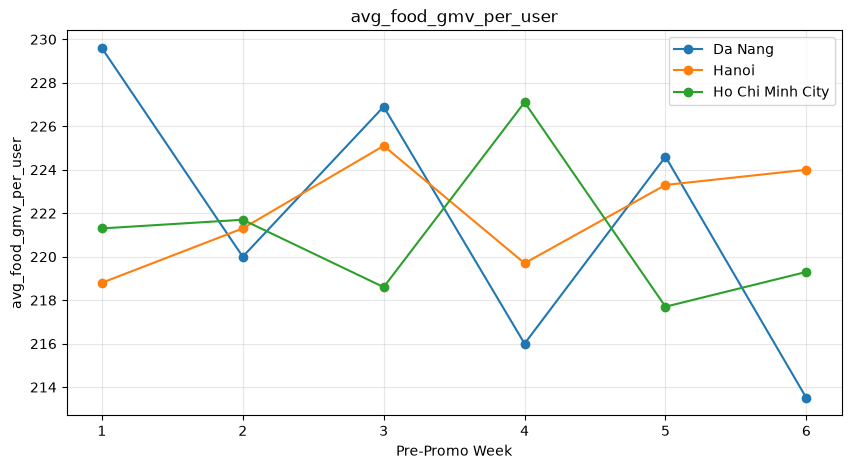

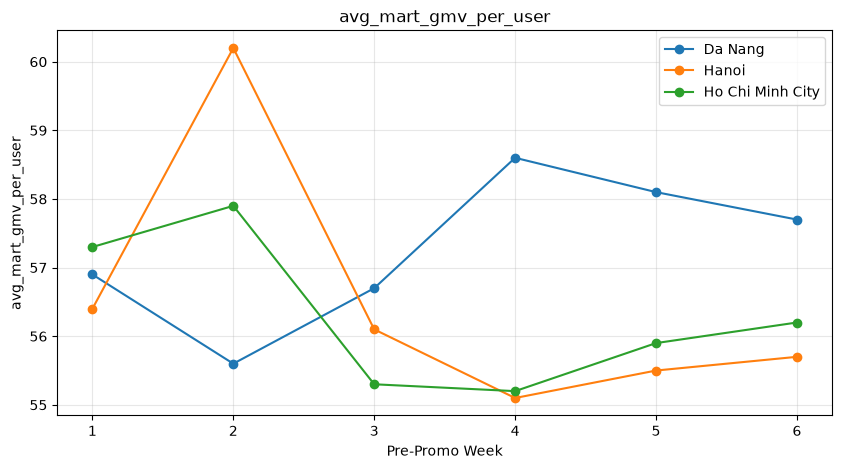

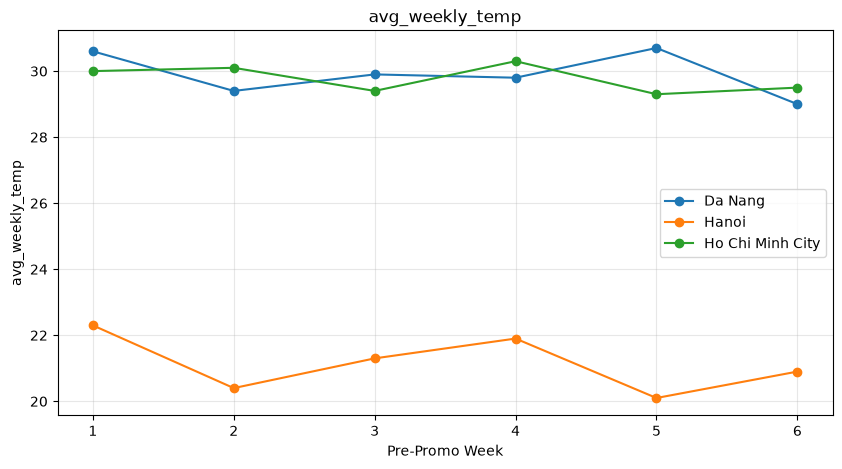

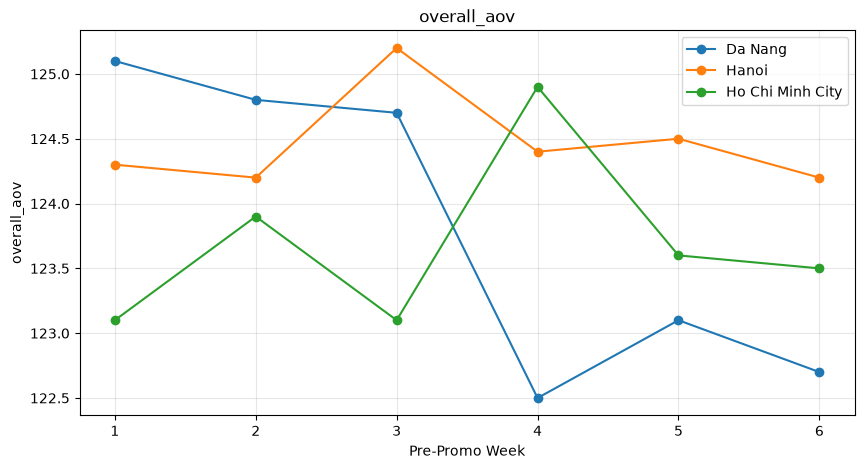

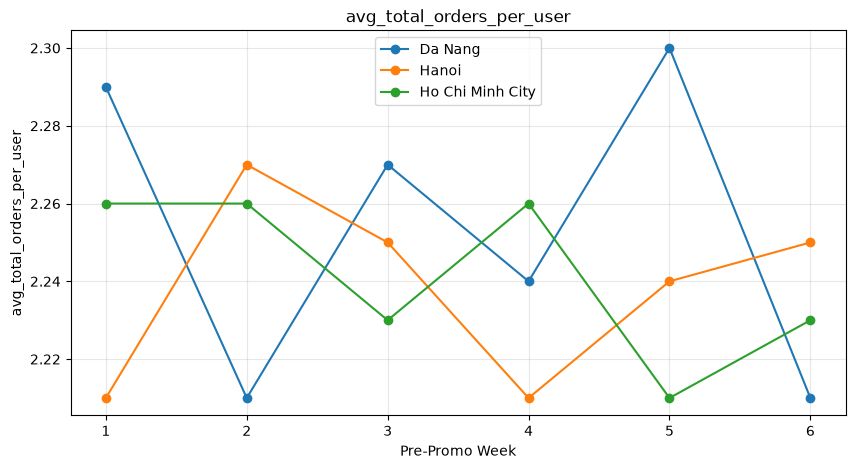

In [ ]:
metrics = [
    "avg_food_gmv_per_user",
    "avg_mart_gmv_per_user",
    "avg_weekly_temp",
    "overall_aov",
    "avg_total_orders_per_user",
]

for metric in metrics:
    plt.figure(figsize=(10, 5))

    for city in df_validation["city"].unique():
        df_city = (
            df_validation[df_validation["city"] == city]
            .sort_values("week_number")
        )

        plt.plot(
            df_city["week_number"],
            df_city[metric],
            marker="o",
            label=city,
        )

    plt.title(metric)
    plt.xlabel("Pre-Promo Week")
    plt.ylabel(metric)
    plt.xticks(range(1, 7))
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

### Correlation Judgement

In [59]:
metrics = [
    "avg_food_gmv_per_user",
    "avg_mart_gmv_per_user",
    "avg_weekly_temp",
    "overall_aov",
    "avg_total_orders_per_user",
]

cities = ["Ho Chi Minh City", "Hanoi", "Da Nang"]

for metric in metrics:
    pivot = (
        df_validation
        .pivot(
            index="week_number",
            columns="city",
            values=metric,
        )
    )

    print(f"\n===== {metric} =====")
    print(pivot[cities].corr())


===== avg_food_gmv_per_user =====
city              Ho Chi Minh City     Hanoi   Da Nang
city                                                  
Ho Chi Minh City          1.000000 -0.722308 -0.388854
Hanoi                    -0.722308  1.000000 -0.094707
Da Nang                  -0.388854 -0.094707  1.000000

===== avg_mart_gmv_per_user =====
city              Ho Chi Minh City     Hanoi   Da Nang
city                                                  
Ho Chi Minh City          1.000000  0.809118 -0.728456
Hanoi                     0.809118  1.000000 -0.882308
Da Nang                  -0.728456 -0.882308  1.000000

===== avg_weekly_temp =====
city              Ho Chi Minh City     Hanoi   Da Nang
city                                                  
Ho Chi Minh City          1.000000  0.516352 -0.137073
Hanoi                     0.516352  1.000000  0.173274
Da Nang                  -0.137073  0.173274  1.000000

===== overall_aov =====
city              Ho Chi Minh City     Hanoi   Da N

### Build-up dataframe for panel

In [64]:
query="""
WITH target_users AS (
SELECT 
user_id, 
city,
CASE 
    WHEN city = 'Ho Chi Minh City' THEN 1 
ELSE 0 
END AS is_treated
FROM users
WHERE 1=1
    AND city IN ('Ho Chi Minh City', 'Hanoi')
),
week_spine AS (
SELECT DISTINCT 
week_number 
FROM transactions
),
date_week_mapping AS (
SELECT DISTINCT 
city, 
date, 
week_number
FROM transactions
WHERE 1=1
    AND city IN ('Ho Chi Minh City', 'Hanoi')
),
city_week_weather AS (
SELECT 
m.city, 
m.week_number, 
ROUND(AVG(w.avg_temperature_celsius), 1) AS avg_weekly_temp
FROM weather_daily w
JOIN date_week_mapping m 
    ON w.city = m.city AND w.date = m.date
GROUP BY 
    m.city, 
    m.week_number
),
user_weekly_activity AS (
SELECT 
t.user_id,
t.week_number,
SUM(CASE WHEN t.service_type = 'GrabMart' THEN t.item_subtotal ELSE 0 END) AS mart_gmv,
SUM(CASE WHEN t.service_type = 'GrabFood' THEN t.item_subtotal ELSE 0 END) AS food_gmv,
SUM(((t.item_subtotal * m.take_rate) + t.delivery_fee_collected) - (t.driver_payout + t.promo_discount * t.is_cross_sell_voucher)) AS cm_per_user
FROM transactions t
JOIN merchants m 
    ON t.merchant_id = m.merchant_id
WHERE 1=1
    AND t.city IN ('Ho Chi Minh City', 'Hanoi')
GROUP BY 
    t.user_id, 
    t.week_number
)
SELECT 
    u.user_id,
    u.city,
    u.is_treated,
    s.week_number,
    (s.week_number - 7) AS relative_week,
    w.avg_weekly_temp,
    COALESCE(a.mart_gmv, 0) AS mart_gmv,
    COALESCE(a.food_gmv, 0) AS food_gmv,
    COALESCE(a.cm_per_user, 0) AS cm_per_user
FROM target_users u
CROSS JOIN week_spine s
LEFT JOIN city_week_weather w 
    ON u.city = w.city 
        AND s.week_number = w.week_number
LEFT JOIN user_weekly_activity a    
    ON u.user_id = a.user_id 
        AND s.week_number = a.week_number;
"""
df_using_for_model = data.query_to_dataframe(query=query)

### OLS Model in regression

Estimating Event-Study DiD model...


/tmp/ipykernel_12930/1926966296.py:31: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
/home/huy/Documents/grab-analytical-entrancetesst/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 28, but rank is 2
  res = self.wald_test(


                            OLS Regression Results                            
Dep. Variable:               mart_gmv   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                 5.619e+23
Date:                Mon, 28 Sep 2026   Prob (F-statistic):           9.43e-13
Time:                        04:19:24   Log-Likelihood:            -6.7649e+05
No. Observations:              119000   AIC:                         1.353e+06
Df Residuals:                  118972   BIC:                         1.353e+06
Df Model:                          27                                         
Covariance Type:              cluster                                         
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept                6.9762 

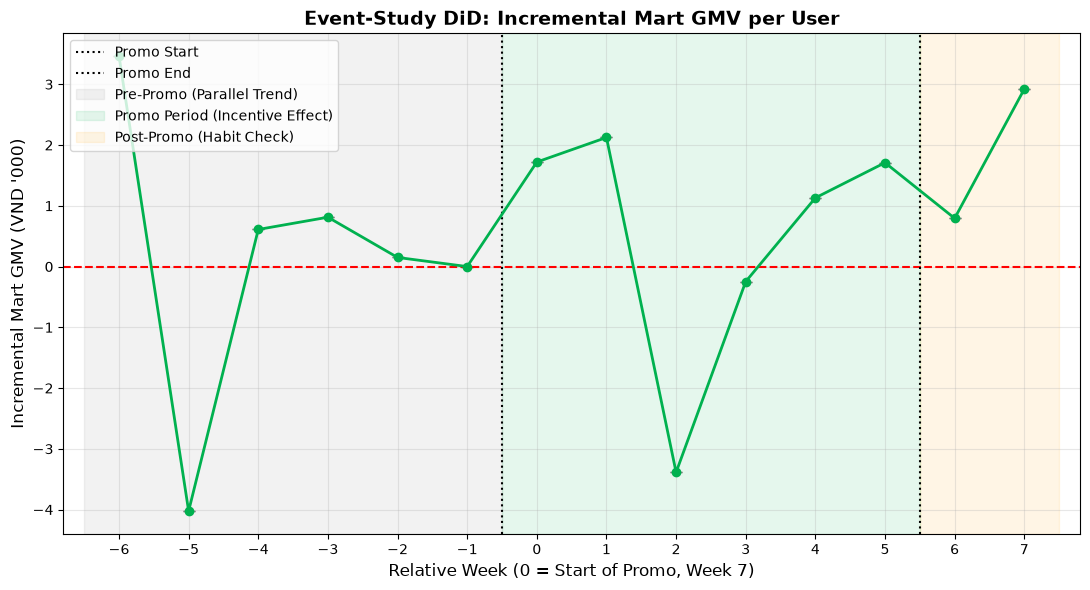

In [80]:
df_panel = df_using_for_model.copy()

df_panel["relative_week"] = df_panel["relative_week"].astype(int)
df_panel["is_treated"] = df_panel["is_treated"].astype(int)

weeks = sorted(df_panel["relative_week"].unique())

interaction_cols = []

for w in weeks:
    if w != -1:
        col_name = f"treat_w_{w if w >= 0 else f'neg_{abs(w)}'}"

        df_panel[col_name] = (
            (df_panel["is_treated"] == 1)
            & (df_panel["relative_week"] == w)
        ).astype(int)

        interaction_cols.append((w, col_name))

formula = (
    f"mart_gmv ~ {' + '.join([col for _, col in interaction_cols])} "
    "+ is_treated + C(week_number) + avg_weekly_temp"
)

print("Estimating Event-Study DiD model...")

model = smf.ols(
    formula,
    data=df_panel
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_panel["city"]}
)

print(model.summary())

coefs = model.params
conf_int = model.conf_int()

event_study_coefs = {}
event_study_cis = {}

event_study_coefs[-1] = 0.0
event_study_cis[-1] = (0.0, 0.0)

for w, col_name in interaction_cols:
    event_study_coefs[w] = coefs[col_name]
    event_study_cis[w] = (
        conf_int.loc[col_name, 0],
        conf_int.loc[col_name, 1],
    )

x = sorted(event_study_coefs.keys())

y = [event_study_coefs[w] for w in x]

y_lower = [
    event_study_cis[w][0]
    for w in x
]

y_upper = [
    event_study_cis[w][1]
    for w in x
]

y_err = [
    np.array(y) - np.array(y_lower),
    np.array(y_upper) - np.array(y),
]

plt.figure(figsize=(11, 6))

plt.errorbar(
    x,
    y,
    yerr=y_err,
    fmt="-o",
    color="#00B14F",
    ecolor="gray",
    elinewidth=1.2,
    capsize=4,
    linewidth=2,
)

plt.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=1.5,
)

plt.axvline(
    -0.5,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Promo Start",
)

plt.axvline(
    5.5,
    color="black",
    linestyle=":",
    linewidth=1.5,
    label="Promo End",
)

plt.axvspan(
    -6.5,
    -0.5,
    color="gray",
    alpha=0.1,
    label="Pre-Promo (Parallel Trend)",
)

plt.axvspan(
    -0.5,
    5.5,
    color="#00B14F",
    alpha=0.1,
    label="Promo Period (Incentive Effect)",
)

plt.axvspan(
    5.5,
    7.5,
    color="orange",
    alpha=0.1,
    label="Post-Promo (Habit Check)",
)

plt.title(
    "Event-Study DiD: Incremental Mart GMV per User",
    fontsize=14,
    fontweight="bold",
)

plt.xlabel(
    "Relative Week (0 = Start of Promo, Week 7)",
    fontsize=12,
)

plt.ylabel(
    "Incremental Mart GMV (VND '000)",
    fontsize=12,
)

plt.xticks(x)
plt.xlim(-6.8, 7.8)

plt.legend(loc="upper left")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Pooled Did

## 1. Define the Promotion and Post-Promotion Periods

We define the campaign periods based on `relative_week`:

* `relative_week < 0`: Pre-promotion / baseline
* `0 <= relative_week <= 5`: Promotion period
* `relative_week > 5`: Post-promotion period

The baseline period is intentionally omitted from the dummy variables. Therefore, the estimated coefficients for the interaction terms are interpreted relative to the **pre-promotion period**.


In [73]:
df_panel = df_using_for_model.copy()

df_panel["during_promo"] = (
    (df_panel["relative_week"] >= 0)
    & (df_panel["relative_week"] <= 5)
).astype(int)

df_panel["post_promo"] = (
    df_panel["relative_week"] > 5
).astype(int)

## 2. Pooled DiD Model Specification

We estimate the following regression:

```math
GMV_{it}
=
\beta_0
+
\beta_1 Treated_i
+
\beta_2 Promo_t
+
\beta_3(Treated_i \times Promo_t)
+
\beta_4 Post_t
+
\beta_5(Treated_i \times Post_t)
+
\gamma_w Week_w
+
\delta Temperature_{it}
+
\epsilon_{it}
```

where:

* $GMV_{it}$ = Mart GMV for observation $i$ at time $t$
* `is_treated` = indicator for whether the observation belongs to the treated group
* `during_promo` = indicator for the promotion period
* `post_promo` = indicator for the post-promotion period
* `C(week_number)` = week fixed effects
* `avg_weekly_temp` = average weekly temperature
* $\epsilon_{it}$ = error term

The most important coefficients are the interaction terms:

### $\beta_3$: Treated × Promotion

This measures the **incremental GMV generated by the campaign during the promotion period**, relative to the pre-promotion baseline and after accounting for the corresponding change in the control group.

### $\beta_5$: Treated × Post-Promotion

This measures the **incremental GMV that remains after the campaign ends**.

A positive and statistically meaningful coefficient suggests that part of the campaign effect may persist beyond the promotion period.


In [74]:
formula_pooled = (
    "mart_gmv ~ is_treated * during_promo + is_treated * post_promo "
    "+ C(week_number) + avg_weekly_temp"
)

## 3. Why Do We Need Interaction Terms?

The DiD effect is not simply the coefficient of `during_promo`.

Instead, we are interested in whether the **treated group changed differently from the control group**.

The interaction:

```math
is\_treated \times during\_promo
```

captures exactly this differential change.

Similarly:

```math
is\_treated \times post\_promo
```

captures whether the treated group continues to behave differently from the control group after the promotion.

Therefore:

| Coefficient                 | Interpretation                                         |
| --------------------------- | ------------------------------------------------------ |
| `is_treated`                | Baseline difference between treated and control groups |
| `during_promo`              | Common time effect during promotion                    |
| `post_promo`                | Common time effect after promotion                     |
| `is_treated × during_promo` | **Incremental campaign effect**                        |
| `is_treated × post_promo`   | **Post-campaign residual effect**                      |

The main business metrics are therefore the two interaction coefficients.


In [75]:
print("Running Pooled DiD model...")

model_pooled = smf.ols(
    formula_pooled,
    data=df_panel
).fit(
    cov_type="cluster",
    cov_kwds={"groups": df_panel["city"]}
)

print(model_pooled.summary())

Running Pooled DiD model...


/tmp/ipykernel_12930/1992836063.py:6: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  ).fit(
/home/huy/Documents/grab-analytical-entrancetesst/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:1988: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 19, but rank is 1
  res = self.wald_test(
/home/huy/Documents/grab-analytical-entrancetesst/.venv/lib/python3.12/site-packages/statsmodels/regression/linear_model.py:2121: RuntimeWarning: invalid value encountered in sqrt
  return np.sqrt(np.diag(self.cov_params()))


                            OLS Regression Results                            
Dep. Variable:               mart_gmv   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                -1.630e+15
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               1.00
Time:                        04:10:08   Log-Likelihood:            -6.7649e+05
No. Observations:              119000   AIC:                         1.353e+06
Df Residuals:                  118982   BIC:                         1.353e+06
Df Model:                          17                                         
Covariance Type:              cluster                                         
                              coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------
Intercept                 

## 4. Clustered Standard Errors

Standard errors are clustered at the **city level**.

This is important because observations within the same city may not be statistically independent.

For example, users in the same city may be exposed to:

* the same local campaign intensity,
* similar weather conditions,
* local demand patterns,
* city-level economic effects.

Clustering by `city` allows observations within the same city to have correlated error terms while still treating different cities as independent clusters.

> **Note:** The model is clustered by `city`, not `user_id`.


## 5. Extract the Core Business Effects

The two coefficients used for business reporting are:

1. **Incremental GMV during promotion**
2. **Incremental GMV after promotion**

The confidence intervals are also extracted to quantify the uncertainty around each estimate.


In [76]:
try:
    coef_promo = model_pooled.params["is_treated:during_promo"]
    coef_post = model_pooled.params["is_treated:post_promo"]

    ci_promo = model_pooled.conf_int().loc["is_treated:during_promo"]
    ci_post = model_pooled.conf_int().loc["is_treated:post_promo"]

except KeyError:
    keys = list(model_pooled.params.keys())

    key_promo = [
        k for k in keys
        if "during_promo" in k and "is_treated" in k
    ][0]

    key_post = [
        k for k in keys
        if "post_promo" in k and "is_treated" in k
    ][0]

    coef_promo = model_pooled.params[key_promo]
    coef_post = model_pooled.params[key_post]

    ci_promo = model_pooled.conf_int().loc[key_promo]
    ci_post = model_pooled.conf_int().loc[key_post]

## 6. Financial Interpretation

The coefficients represent the estimated **incremental Mart GMV per user per week**, assuming `mart_gmv` is measured at that level.

### Promotion Period

```math
Incremental\ GMV_{promo}
=
\beta_{Treated \times Promo}
```

This represents the additional GMV associated with the campaign beyond what would have occurred based on:

* the treated group's baseline level,
* the control group's time trend,
* weekly effects,
* and the temperature control variable.

### Post-Promotion Period

```math
Incremental\ GMV_{post}
=
\beta_{Treated \times Post}
```

This represents the estimated GMV difference that persists after the campaign ends.

This can be used as an indication of **retention / habit formation**, but it should not automatically be interpreted as permanent customer behavior without a longer post-treatment observation window.


In [77]:
print("\n" + "=" * 50)
print("FINANCIAL REPORTING METRICS")
print("=" * 50)

print(
    f"1. Incremental GMV / user / week (Promo): "
    f"{coef_promo:.2f} k VND"
)

print(
    f"2. Incremental GMV / user / week (Post-Promo): "
    f"{coef_post:.2f} k VND"
)

print("=" * 50)


FINANCIAL REPORTING METRICS
1. Incremental GMV / user / week (Promo): 12.43 k VND
2. Incremental GMV / user / week (Post-Promo): 1.41 k VND


## 7. Visualizing the Estimated Treatment Effect

The chart below summarizes the estimated treatment effect across three stages:

1. **Pre-Promotion:** baseline = 0
2. **Promotion:** estimated incremental campaign effect
3. **Post-Promotion:** estimated remaining effect

The error bars represent the **95% confidence intervals** around the estimated effects.

The zero line represents **no incremental treatment effect**.

Therefore:

* Effect above zero → positive incremental GMV
* Effect below zero → negative incremental GMV
* Confidence interval crossing zero → effect is not statistically distinguishable from zero at the 5% level


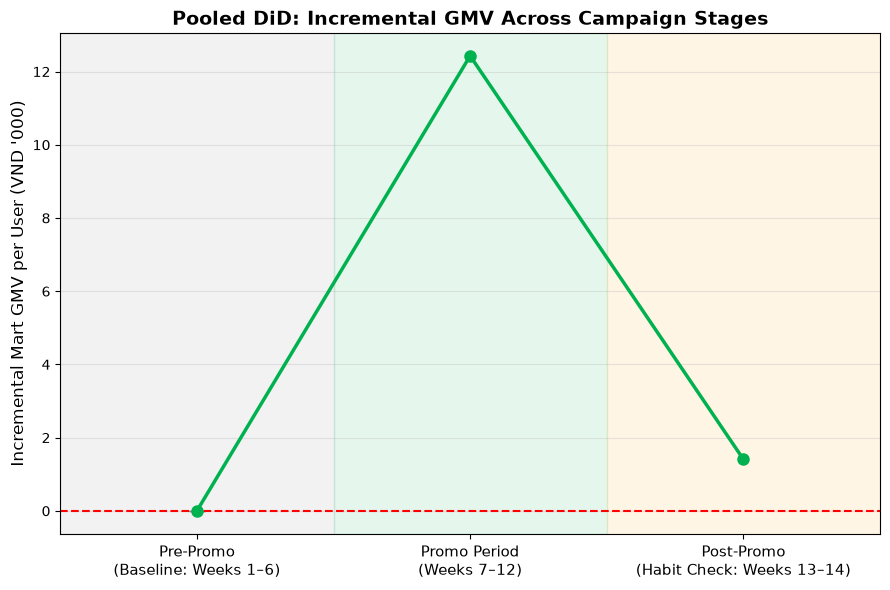

In [78]:
stages_x = [0, 1, 2]

stages_labels = [
    "Pre-Promo\n(Baseline: Weeks 1–6)",
    "Promo Period\n(Weeks 7–12)",
    "Post-Promo\n(Habit Check: Weeks 13–14)",
]

effects = [0.0, coef_promo, coef_post]

err_lower = [
    0.0,
    coef_promo - ci_promo[0],
    coef_post - ci_post[0],
]

err_upper = [
    0.0,
    ci_promo[1] - coef_promo,
    ci_post[1] - coef_post,
]

yerr = [err_lower, err_upper]

fig, ax = plt.subplots(figsize=(9, 6))

ax.errorbar(
    stages_x,
    effects,
    yerr=yerr,
    fmt="-o",
    color="#00B14F",
    ecolor="gray",
    elinewidth=1.5,
    capsize=6,
    markersize=8,
    linewidth=2.5,
)

ax.axhline(
    0,
    color="red",
    linestyle="--",
    linewidth=1.5,
)

ax.axvspan(
    -0.5,
    0.5,
    color="gray",
    alpha=0.1,
)

ax.axvspan(
    0.5,
    1.5,
    color="#00B14F",
    alpha=0.1,
)

ax.axvspan(
    1.5,
    2.5,
    color="orange",
    alpha=0.1,
)

ax.set_xticks(stages_x)
ax.set_xticklabels(stages_labels, fontsize=11)

ax.set_xlim(-0.5, 2.5)

ax.set_ylabel(
    "Incremental Mart GMV per User (VND '000)",
    fontsize=12,
)

ax.set_title(
    "Pooled DiD: Incremental GMV Across Campaign Stages",
    fontsize=14,
    fontweight="bold",
)

for i, (x, y) in enumerate(zip(stages_x, effects)):
    if i > 0:
        offset = (
            err_upper[i] + 1.5
            if y >= 0
            else -(err_lower[i] + 1.5)
        )

        ax.text(
            x,
            y + offset,
            f"{y:.1f}k",
            ha="center",
            va="bottom" if y >= 0 else "top",
            fontweight="bold",
            fontsize=11,
        )

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

## 8. How to Read the Results

The analysis should answer three key business questions.

### 1. Did the campaign generate incremental GMV?

Look at:

```math
\beta_{Treated \times Promo}
```

If the coefficient is positive and its confidence interval does not include zero, there is evidence that the campaign generated incremental GMV.

### 2. How large was the campaign effect?

The coefficient can be translated into a financial impact:

```math
Total\ Incremental\ GMV
=
Incremental\ GMV/User/Week
\times
Number\ of\ Treated\ Users
\times
Number\ of\ Promo\ Weeks
```

This converts the regression result into a P&L-relevant business metric.

### 3. Did the effect persist after the campaign?

Look at:

```math
\beta_{Treated \times Post}

```

A positive post-promotion coefficient suggests that some of the incremental behavior remains after the campaign.

However, this should be interpreted as **evidence of persistence**, rather than definitive proof of long-term habit formation, especially when the post-promotion observation window is short.


## 9. Important Caveats

### Parallel Trends

The validity of the DiD estimate depends heavily on the assumption that treated and control groups would have followed parallel trends in the absence of the campaign.

This should ideally be validated by plotting the treated and control groups during the **pre-promotion period**.

### Treatment Selection

If treatment was not randomly assigned, treated users/cities may systematically differ from controls.

For example, treated users may already have higher GMV or stronger engagement.

### Short Post-Promotion Window

The current post-promotion period covers only a limited number of weeks.

Therefore, the post-promotion coefficient should be interpreted as:

> **Short-term persistence of the campaign effect**

rather than long-term customer retention.

### Cluster Level

Because standard errors are clustered by `city`, the inference assumes that cities provide the relevant independent clusters.

If treatment is assigned at the city level, city-level clustering is particularly important.

### Coefficient ≠ Total Campaign ROI

The DiD coefficient measures incremental GMV, not profit.

To estimate campaign ROI, incremental GMV should subsequently be converted into:

```math
Incremental\ Profit
=
Incremental\ GMV
\times
Contribution\ Margin
-
Campaign\ Cost
```

This allows the DiD output to be connected directly to the P&L.


### Query-base (DRAFT)

### Check-whether: in Promo Duration -- is there any user | not aware about the promotion

_no_used_any_transaction_in_promo_duration_

`sql_path`: query/user_no_aware_promotion.sql

user_segment | cnt_user | Food_users | Mart_users
-------------|----------|------------|-----------
High Value|29|29|29
Occasional|288|288|167
Regular|168|168|152
Voucher Hunter|68|68|63

In [22]:
query=data.parse_query(query_path="query/user_no_aware_promotion.sql")
data.query_to_dataframe(query=query)

,user_segment,cnt_user,Food_users,Mart_users
0,High Value,29,29,29
1,Occasional,288,288,167
2,Regular,168,168,152
3,Voucher Hunter,68,68,63


### Segment (existed | new) in each duration (Before-Promo | Promo | After-Promo) 

`sql_path`: "query/classfiy_users_new_new_or_exists.sql"

||period|user_type|unique_users|n_transactions
|-|------|---------|------------|--------------
|0|Post-Promo|existed-mart-user|2634|4225
|1|Pre-Promo|existed-mart-user|3984|12543
|2|Promo|existed-mart-user|4215|20420
|3|Post-Promo|new-mart-user|385|655
|4|Pre-Promo|new-mart-user|598|1974
|5|Promo|new-mart-user|643|3210

In [23]:
query=data.parse_query(query_path="query/classify_users_new_or_exist.sql")
data.query_to_dataframe(query=query)

,period,user_type,unique_users,n_transactions
0,Post-Promo,existed-mart-user,2634,4225
1,Pre-Promo,existed-mart-user,3984,12543
2,Promo,existed-mart-user,4215,20420
3,Post-Promo,new-mart-user,385,655
4,Pre-Promo,new-mart-user,598,1974
5,Promo,new-mart-user,643,3210


### who actual drove the GROWTH ?

In [24]:
query=data.parse_query(query_path="query/segment_drive_growth.sql")
data.query_to_dataframe(query=query)

,city,user_segment,user_type,gross_gmv_M_vnd,service_type
0,Ho Chi Minh City,High Value,existed-mart-user,4472.2,GrabFood
1,Ho Chi Minh City,Regular,existed-mart-user,2950.7,GrabFood
2,Ho Chi Minh City,Voucher Hunter,existed-mart-user,1558.7,GrabFood
3,Ho Chi Minh City,High Value,new-mart-user,795.6,GrabFood
4,Ho Chi Minh City,Regular,existed-mart-user,734.4,GrabMart
5,Ho Chi Minh City,Occasional,existed-mart-user,509.7,GrabFood
6,Ho Chi Minh City,Regular,new-mart-user,441.0,GrabFood
7,Ho Chi Minh City,High Value,existed-mart-user,406.7,GrabMart
8,Ho Chi Minh City,Voucher Hunter,existed-mart-user,318.7,GrabMart
9,Ho Chi Minh City,Voucher Hunter,new-mart-user,254.0,GrabFood


### Check PnL: structure

In [25]:
query = """
select
city,
user_segment,
count(user_id) as cnt_user
from users
where 1=1
group by
    city,
    user_segment
"""
data.query_to_dataframe(query=query)

,city,user_segment,cnt_user
0,Da Nang,High Value,408
1,Da Nang,Occasional,307
2,Da Nang,Regular,919
3,Da Nang,Voucher Hunter,366
4,Hanoi,High Value,738
5,Hanoi,Occasional,489
6,Hanoi,Regular,1604
7,Hanoi,Voucher Hunter,669
8,Ho Chi Minh City,High Value,984
9,Ho Chi Minh City,Occasional,730
